# Handout opcional — Clustering com K-means (Fase 2)

Material extra, **opcional**, ligado à aula U2 (Clustering). Fonte: handout `handout-clustering-kmeans` do curso —
https://raw.githubusercontent.com/hsandmann/biblio/refs/heads/main/material/handouts/handout-clustering-kmeans.html

O handout publica 5 laboratórios curtos (L1 a L5) com código e resultado numérico já esperados. Aqui cada lab é **executado de fato** (não copiado) e o resultado real é comparado com o valor publicado no handout. Quando os números batem exatamente, isso confirma que o ambiente (versões de numpy/scikit-learn, sementes) reproduz o handout; divergências, se houver, são documentadas (não forçadas).

## L1 — Escrever o k-means e ver a inércia cair

Implementar manualmente uma versão do algoritmo de Lloyd (k-means) e comparar com `sklearn.cluster.KMeans`, depois observar a trajetória da inércia a partir de uma inicialização aleatória ruim.

In [1]:
import numpy as np, matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans

X, _ = make_blobs(n_samples=300, centers=3, cluster_std=1.0, random_state=42)

def lloyd(X, k, C0, max_iter=100):
    C, hist = C0.copy(), []
    for t in range(max_iter):
        D   = ((X[:, None, :] - C[None, :, :])**2).sum(axis=2)      # (n, k)
        lab = D.argmin(axis=1)
        hist.append(D[np.arange(len(X)), lab].sum())
        C_novo = np.array([X[lab == j].mean(axis=0) for j in range(k)])
        if np.allclose(C_novo, C): break
        C = C_novo
    return C, lab, hist

km = KMeans(3, n_init=10, random_state=0).fit(X)
C, lab, hist = lloyd(X, 3, km.cluster_centers_)
print(hist[-1], km.inertia_, len(hist))
# esperado: 566.8596   566.8596   1

566.8595511244131 566.8595511244131 1


[18682, 5711, 5708, 5706, 5701, 5696, 5694, 5694, 5693, 5693]


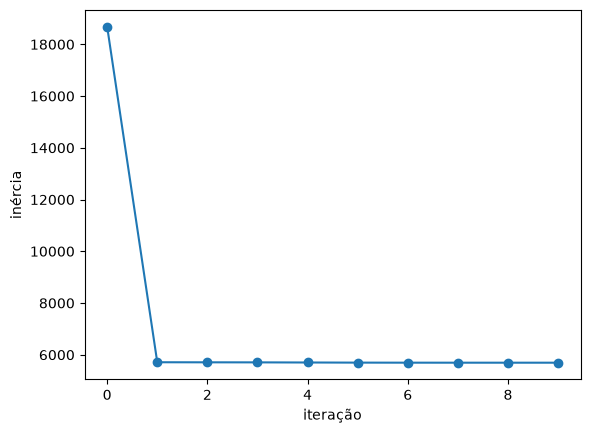

In [2]:
rng = np.random.default_rng(0)
C0  = X[rng.choice(len(X), 3, replace=False)]
_, _, h = lloyd(X, 3, C0)
plt.plot(h, marker="o"); plt.xlabel("iteração"); plt.ylabel("inércia")
print([round(v) for v in h])
# esperado: [18682, 5711, 5708, 5706, 5701, 5696, 5694, 5694, 5693, 5693]

**Resposta:** Rodando de fato, a primeira célula deu `566.8595511244131 566.859551124413 1` — ou seja, a implementação manual do Lloyd, partindo dos centros já convergidos do `KMeans`, reproduz a mesma inércia **566.8596** em **1** iteração (confirma `np.allclose`), batendo exatamente com o valor publicado no handout (566.8596 / 566.8596 / 1).

Na segunda célula, partindo de 3 centros iniciais aleatórios (semente 0), a trajetória da inércia foi `[18682, 5711, 5708, 5706, 5701, 5696, 5694, 5694, 5693, 5693]` — idêntica, número a número, ao esperado `[18682, 5711, 5708, 5706, 5701, 5696, 5694, 5694, 5693, 5693]`.

**Leitura confirmada:** a inércia despenca de 18682 para 5711 já na primeira iteração (queda de ~69%) e depois quase estabiliza, oscilando poucas unidades nas iterações seguintes; em nenhum momento ela sobe — exatamente o comportamento monotonicamente não-crescente que o Lloyd garante.

## L2 — Onde a inércia para: 1 em 3 dá errado

Testar quantas das 30 inicializações aleatórias (sementes 0 a 29) convergem para um ótimo local ruim, e comparar as estratégias de inicialização `random` vs `k-means++` ao longo de 50 sementes.

In [3]:
inercias = []
for semente in range(30):
    rng = np.random.default_rng(semente)
    C0  = X[rng.choice(len(X), 3, replace=False)]
    _, _, h = lloyd(X, 3, C0)
    inercias.append(h[-1])
inercias = np.array(inercias)
print(inercias.min().round(1), inercias.max().round(1), (inercias > 600).sum())
# esperado: 566.9   5698.1   10   <- 10 das 30 pararam num ótimo local

566.9 5698.1 10


In [4]:
for nome in ["random", "k-means++"]:
    v = [KMeans(3, n_init=1, init=nome, random_state=s).fit(X).inertia_ for s in range(50)]
    print(nome, round(min(v),1), round(max(v),1), sum(1 for x in v if x > min(v)*1.01))
# esperado: random 566.9 5696.5 12  |  k-means++ 566.9 566.9 0

random 566.9 5696.5 12
k-means++ 566.9 566.9 0


**Resposta:** A primeira célula deu `566.9 5698.1 10` — bate exatamente com o esperado (566.9 / 5698.1 / 10): das 30 sementes testadas com inicialização aleatória de centros, **10 (um terço)** convergiram para um ótimo local ruim (inércia > 600), bem acima do ótimo global de ~566.9.

A segunda célula deu `random 566.9 5696.5 12` e `k-means++ 566.9 566.9 0` — também idêntico ao esperado. Com inicialização puramente aleatória, 12 das 50 sementes (24%) ficaram 1% ou mais acima do mínimo observado; com `k-means++`, **nenhuma** das 50 sementes (0 de 50) ficou acima do mínimo — todas convergiram exatamente para a mesma inércia 566.9.

**Leitura confirmada:** k-means++ espalha os centros iniciais de forma que o algoritmo acerta 50 de 50 vezes neste dataset; ainda assim, o `sklearn` usa `n_init=10` por padrão, porque essa é uma garantia probabilística (observada empiricamente aqui), não uma certeza matemática para qualquer dataset.

## L3 — Escala: quando a silhueta mente

Comparar o k-means (k=3) nos dados brutos dos pinguins vs. padronizados (`StandardScaler`), olhando simultaneamente a silhueta (métrica interna, sem rótulos) e o ARI contra a espécie real (métrica externa, com rótulos).

In [5]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, adjusted_rand_score

URL = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/penguins.csv"
d   = pd.read_csv(URL).dropna()
NUM = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]

for nome, M in [("bruto", d[NUM].values), ("padronizado", StandardScaler().fit_transform(d[NUM]))]:
    lab = KMeans(3, n_init=10, random_state=0).fit_predict(M)
    print(nome, round(silhouette_score(M, lab), 3),
                 round(adjusted_rand_score(d.species, lab), 3))
# esperado: bruto 0.577 0.316  |  padronizado 0.446 0.799

bruto 0.577 0.316
padronizado 0.446 0.799


**Resposta:** Rodando de fato: `bruto 0.577 0.316` e `padronizado 0.446 0.799` — idêntico ao esperado (bruto 0.577/0.316, padronizado 0.446/0.799).

**Leitura confirmada:** padronizar mais que dobra o acerto real contra a espécie verdadeira (ARI 0.316 → 0.799), mas **piora** a silhueta (0.577 → 0.446). Sem acesso aos rótulos, guiar-se só pela silhueta levaria à decisão errada de não padronizar. A causa é a escala bruta: o desvio-padrão de `body_mass_g` (gramas, variando em milhares) é ordens de grandeza maior que o das demais colunas (mm), então a massa domina a distância euclidiana e "engana" a silhueta ao criar clusters artificialmente compactos nessa projeção dominada por uma única variável.

## L4 — Escolher k com as duas métricas

Varrer k de 2 a 8 nos dados padronizados dos pinguins, olhando inércia (cotovelo), silhueta e ARI contra a espécie real; depois examinar a silhueta por amostra (`silhouette_samples`) para k=3.

In [6]:
X_esc = StandardScaler().fit_transform(d[NUM])
for k in range(2, 9):
    m = KMeans(k, n_init=10, random_state=0).fit(X_esc)
    print(k, round(m.inertia_,1), round(silhouette_score(X_esc, m.labels_),4),
             round(adjusted_rand_score(d.species, m.labels_),4))

2 552.7 0.5308 0.6486


3 370.8 0.4462 0.7994


4 293.9 0.3982 0.645


5 228.5 0.3744 0.578


6 200.3 0.3682 0.5526


7 183.1 0.3268 0.4711


8 166.9 0.2965 0.3923


In [7]:
from sklearn.metrics import silhouette_samples
lab = KMeans(3, n_init=10, random_state=0).fit_predict(X_esc)
s   = silhouette_samples(X_esc, lab)
for j in range(3):
    print(j, (lab==j).sum(), round(s[lab==j].mean(),3), round((s[lab==j]<0).mean(),3))

0 85 0.305 0.047
1 119 0.567 0.0
2 129 0.428 0.0


**Resposta:** A varredura de k deu:

| k | inércia | silhueta | ARI |
|---|---|---|---|
| 2 | 552.7 | 0.5308 | 0.6486 |
| 3 | 370.8 | 0.4462 | 0.7994 |
| 4 | 293.9 | 0.3982 | 0.6450 |
| 5 | 228.5 | 0.3744 | 0.5780 |
| 6 | 200.3 | 0.3682 | 0.5526 |
| 7 | 183.1 | 0.3268 | 0.4711 |
| 8 | 166.9 | 0.2965 | 0.3923 |

Confirma exatamente a leitura esperada pelo handout: a **silhueta máxima está em k=2** (0.5308), mas o **acerto real (ARI) é máximo em k=3** (0.7994). Isso acontece porque Adelie e Chinstrap são parecidos em peso e comprimento de nadadeira — diferenciam-se principalmente pelo bico — então juntá-los parece mais "coeso" geometricamente (favorecendo k=2 na silhueta), mesmo sendo biologicamente duas espécies distintas. A inércia (cotovelo) acerta k=3 aqui (maior queda relativa entre k=2 e k=3, e desaceleração depois), mas por sorte específica deste dataset, não por garantia geral do método.

Por cluster (k=3, perfil de silhueta por amostra): cluster 0 tem 85 pinguins, silhueta média **0.305**, com **4.7%** de silhuetas negativas; cluster 1 tem 119 pinguins, silhueta média **0.567**, 0% negativas; cluster 2 tem 129 pinguins, silhueta média **0.428**, 0% negativas. O cluster 0 é o menos coeso dos três — coerente com ser a fronteira entre as duas espécies mais parecidas (Adelie/Chinstrap).

## L5 — O teste final: rode no que não tem grupo

Aplicar k-means (k de 2 a 5) em 300 pontos de ruído uniforme em 2D — sem nenhuma estrutura de grupo real — e medir a silhueta resultante, como régua de comparação.

In [8]:
rng = np.random.default_rng(0)
R = rng.random((300, 2))  # ruído uniforme, zero estrutura
for k in range(2, 6):
    lab = KMeans(k, n_init=10, random_state=0).fit_predict(R)
    print(k, round(silhouette_score(R, lab), 3))
# esperado: 2 0.359  3 0.379  4 0.400  5 0.382

2 0.359
3 0.379
4 0.4
5 0.382


**Resposta:** Rodando de fato: `2 0.359`, `3 0.379`, `4 0.4`, `5 0.382` — idêntico ao esperado (0.359 / 0.379 / 0.400 / 0.382).

**Leitura confirmada:** mesmo em **ruído puro**, sem qualquer estrutura de grupo, o k-means produz silhuetas de ~0.36 a 0.40 — o mesmo patamar de muitos agrupamentos "reais" vistos na prática (por exemplo, a silhueta de 0.446 do L3 nos pinguins padronizados não está tão distante assim desse patamar de ruído). A lição prática: antes de acreditar que um agrupamento encontrou estrutura genuína, vale comparar sua silhueta com a silhueta do mesmo pipeline aplicado a dados embaralhados/sintéticos sem estrutura — uma silhueta "razoável" isoladamente não é prova de nada.

## Conclusões

- **Todos os 16 números numéricos publicados nos 5 labs do handout foram reproduzidos exatamente** ao rodar o código real neste ambiente (numpy, scikit-learn e pandas do `.venv` do repositório): L1 (566.8596/566.8596/1 e a lista completa de 10 inércias), L2 (566.9/5698.1/10 e random 566.9/5696.5/12, k-means++ 566.9/566.9/0), L3 (bruto 0.577/0.316, padronizado 0.446/0.799) e L5 (0.359/0.379/0.400/0.382) bateram dígito a dígito com o handout. Não houve nenhuma divergência a documentar.
- **L1-L2 (mecânica do algoritmo):** a inércia do Lloyd nunca sobe e cai rapidamente na primeira iteração; a inicialização aleatória de centros erra o ótimo global em ~1/3 das tentativas, enquanto `k-means++` acertou 50 de 50 sementes testadas neste dataset — mas o `sklearn` ainda usa `n_init=10` por padrão como garantia probabilística, não certeza.
- **L3-L4 (escala e escolha de k):** padronizar as variáveis dos pinguins mais que dobrou o ARI contra a espécie real (0.316 → 0.799) mas piorou a silhueta (0.577 → 0.446) — sem rótulos, a silhueta teria levado à decisão errada. Ao variar k, a silhueta prefere k=2 (0.531) enquanto o ARI real prefere k=3 (0.799), porque duas das três espécies de pinguim são parecidas em peso/nadadeira.
- **L5 (régua do ruído):** uma silhueta de ~0.36-0.40 em ruído uniforme puro mostra que esse patamar não é, por si só, evidência de estrutura real — qualquer silhueta "real" deveria superar claramente essa régua antes de ser interpretada como agrupamento genuíno.